# Lavrentiev gap: conforming P1 vs. nonconforming Crouzeix–Raviart (CR), with the decomposition–coordination method

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jfbonder/glaplace/blob/main/notebooks/glaplace_cr_lavrentiev.ipynb)

For integrands with a **Lavrentiev gap** every conforming finite element space (functions in $W^{1,\infty}$) converges to the infimum over
*Lipschitz/smooth* functions, $m_{\mathcal H}$, which is larger than the true minimum $m_{\mathcal W}$ over the energy space
(Carstensen–Ortner 2010). The **Crouzeix–Raviart** element (midpoint continuity, nonconforming) converges to the $\mathcal W$-minimiser
under suitable assumptions (Balci–Ortner–Storn 2022, one-point quadrature $\varphi(x_T,\cdot)$).

**Implementation.** The broken gradient of a CR function is constant on each triangle, exactly like the P1 gradient. Hence $\nu,\eta$ (piecewise constants)
and the pointwise nonlinear step are *identical* to the P1 code; only the space of $u$ changes (`glaplace/cr.py`, the P1 code is untouched).
At each mesh the iteration is a finite-dimensional ADMM, so it converges for every $r>0$ (Theorem C of the paper).
What happens as $h\to0$ is **not** covered by our theory: it is the Lavrentiev question.

**Test problems** (Zhikov checkerboard; $\Omega=(-1,1)^2$, $f=0$, boundary data $\lambda u_0$, $u_0=1$ for $|x_1|<x_2$, $-1$ for $|x_1|<-x_2$, $x_2/|x_1|$ otherwise):

* **p(x)-Laplacian with discontinuous $p$:** $G=t^{p(x)}/p(x)$, $p=3$ if $|x_1|<|x_2|$, $p=3/2$ otherwise;
* **two-phase with discontinuous $a$:** $G=t^{3/2}/(3/2)+a(x)\,t^3/3$, $a=1$ if $|x_1|<|x_2|$, $a=0$ otherwise.

We compare the **energies** $F_h(u_h)=\sum_T|T|\,G(x_T,\nabla_h u_h|_T)$ (the same formula for both schemes). No exact solution is available except for $\lambda=1$, $p(x)$ problem
($u=x_2$, $F=2$). **Run all cells.**

## 1. Package source (self-contained)

In [1]:
!pip -q install triangle meshio sympy 2>&1 | tail -1
!mkdir -p glaplace

In [2]:
%%writefile glaplace/__init__.py
"""glaplace: g-Laplacian solver (decomposition-coordination / ADMM + P1 FEM) on general 2D domains.

-div( g(x,|grad u|) grad u/|grad u| ) = f,  g = dG/dt,  G a Young function (p-q, p log^a, exp, two-phase, ...).
Built from the p(x)-Laplacian code `pxlaplace` (Aragon, Fernandez Bonder, Rubio).
"""
from .mesh import (Mesh, rectangle_mesh, polygon_mesh, sdf_mesh, disk_mesh,
                   from_txt, from_meshio, boundary_nodes_from_triangles)
from .fem import P1Space
from .young import (Young, PowerLaw, PLog, Exp, ExpLiteral, Custom, Sum, from_expr, pq, check_young)
from .solver import GLaplaceSolver, solve, SolveResult
from .nonlinear import solve_scalar, update_nu
from . import exact

__all__ = ["Mesh", "rectangle_mesh", "polygon_mesh", "sdf_mesh", "disk_mesh", "from_txt", "from_meshio",
           "boundary_nodes_from_triangles", "P1Space", "Young", "PowerLaw", "PLog", "Exp", "ExpLiteral", "Custom",
           "Sum", "from_expr", "pq", "check_young", "GLaplaceSolver", "solve", "SolveResult", "solve_scalar",
           "update_nu", "exact"]

Writing glaplace/__init__.py


In [3]:
%%writefile glaplace/mesh.py
"""Triangular meshes for arbitrary 2D domains.

A :class:`Mesh` only needs ``vertices (Nn,2)``, ``triangles (Nt,3)`` and the
indices of the Dirichlet (boundary) nodes -- exactly the three arrays the
MatLab code reads (vertex_coordinates, elem_vertices, dirichlet).  Everything
else in the package is domain independent, so any mesher can be plugged in.
"""
from __future__ import annotations
from dataclasses import dataclass, field
import numpy as np


@dataclass
class Mesh:
    vertices: np.ndarray          # (Nn, 2) float
    triangles: np.ndarray         # (Nt, 3) int, counter-clockwise
    dirichlet: np.ndarray         # (Nd,)   int, boundary node indices

    def __post_init__(self):
        self.vertices = np.ascontiguousarray(self.vertices, dtype=float)
        self.triangles = np.ascontiguousarray(self.triangles, dtype=np.int64)
        self.dirichlet = np.unique(np.asarray(self.dirichlet, dtype=np.int64))
        self._orient()

    def _orient(self):
        """Make every triangle counter-clockwise (positive area)."""
        v = self.vertices[self.triangles]
        d = ((v[:, 1, 0] - v[:, 0, 0]) * (v[:, 2, 1] - v[:, 0, 1])
             - (v[:, 2, 0] - v[:, 0, 0]) * (v[:, 1, 1] - v[:, 0, 1]))
        flip = d < 0
        if flip.any():
            self.triangles[flip] = self.triangles[flip][:, [0, 2, 1]]

    @property
    def n_nodes(self): return self.vertices.shape[0]
    @property
    def n_elems(self): return self.triangles.shape[0]

    def plot(self, u=None, ax=None, **kw):
        import matplotlib.pyplot as plt
        import matplotlib.tri as mtri
        tri = mtri.Triangulation(self.vertices[:, 0], self.vertices[:, 1], self.triangles)
        if ax is None:
            ax = plt.gca()
        if u is None:
            ax.triplot(tri, lw=0.4, **kw)
        else:
            c = ax.tripcolor(tri, u, shading="gouraud", **kw)
            ax.figure.colorbar(c, ax=ax)
        ax.set_aspect("equal")
        return ax


def boundary_nodes_from_triangles(triangles) -> np.ndarray:
    """Nodes on edges that belong to exactly one triangle (the boundary)."""
    t = np.asarray(triangles)
    edges = np.vstack([t[:, [0, 1]], t[:, [1, 2]], t[:, [2, 0]]])
    edges = np.sort(edges, axis=1)
    uniq, counts = np.unique(edges, axis=0, return_counts=True)
    return np.unique(uniq[counts == 1])


# --------------------------------------------------------------------------
# Rectangle (same layout as gen_mesh_rectangle.m, but in memory)
# --------------------------------------------------------------------------
def rectangle_mesh(n: int, m: int | None = None, xmin=0.0, xmax=1.0, ymin=0.0, ymax=1.0) -> Mesh:
    """Uniform mesh of [xmin,xmax]x[ymin,ymax]: n x m cells, 2 triangles each."""
    m = n if m is None else m
    x = np.linspace(xmin, xmax, n + 1)
    y = np.linspace(ymin, ymax, m + 1)
    X, Y = np.meshgrid(x, y)                      # row i -> y_i, col j -> x_j
    V = np.column_stack([X.ravel(), Y.ravel()])
    idx = np.arange((n + 1) * (m + 1)).reshape(m + 1, n + 1)
    a, b = idx[:-1, :-1].ravel(), idx[:-1, 1:].ravel()
    c, d = idx[1:, 1:].ravel(), idx[1:, :-1].ravel()
    T = np.vstack([np.column_stack([a, b, d]), np.column_stack([b, c, d])])
    bd = np.concatenate([idx[0, :], idx[-1, :], idx[:, 0], idx[:, -1]])
    return Mesh(V, T, bd)


# --------------------------------------------------------------------------
# Polygon (with holes) via Shewchuk's Triangle (optional dependency)
# --------------------------------------------------------------------------
def polygon_mesh(outer, holes=(), hole_points=(), max_area=None, min_angle=25.0) -> Mesh:
    """Quality triangulation of a polygon with optional polygonal holes.

    outer       : (k,2) vertices of the outer boundary (any orientation)
    holes       : iterable of (k_i,2) arrays, boundaries of the holes
    hole_points : (not needed; a point inside every hole is computed automatically)
    max_area    : maximum triangle area (controls resolution)
    Requires the ``triangle`` package (pip install triangle).
    """
    try:
        import triangle as tr
    except ImportError as e:                                   # pragma: no cover
        raise ImportError("polygon_mesh needs `pip install triangle`; "
                          "alternatively use sdf_mesh()") from e
    outer = np.asarray(outer, float)
    pts, segs, hpts = [outer], [], []
    off = len(outer)
    segs.append(np.column_stack([np.arange(off), (np.arange(off) + 1) % off]))
    for h in holes:
        h = np.asarray(h, float)
        k = len(h)
        segs.append(np.column_stack([off + np.arange(k), off + (np.arange(k) + 1) % k]))
        pts.append(h)
        hpts.append(_interior_point(h))
        off += k
    A = dict(vertices=np.vstack(pts), segments=np.vstack(segs))
    if hpts:
        A["holes"] = np.array(hpts)
    opts = f"pq{min_angle:g}"
    if max_area is not None:
        opts += f"a{max_area:.10g}"
    B = tr.triangulate(A, opts)
    T = B["triangles"]
    return Mesh(B["vertices"], T, boundary_nodes_from_triangles(T))


def _interior_point(poly):
    """A point strictly inside a simple polygon (centroid of an ear)."""
    n = len(poly)
    from matplotlib.path import Path
    path = Path(poly)
    c = poly.mean(axis=0)
    if path.contains_point(c):
        return c
    for i in range(n):
        tri = poly[[i, (i + 1) % n, (i + 2) % n]]
        p = tri.mean(axis=0)
        if path.contains_point(p):
            return p
    raise ValueError("could not find an interior point of the hole")


# --------------------------------------------------------------------------
# Implicit domains via signed distance function (DistMesh-lite, numpy/scipy)
# --------------------------------------------------------------------------
def sdf_mesh(sdf, bbox, h0, fh=None, seed=0, max_iter=300, fixed=None, verbose=False) -> Mesh:
    """Mesh {sdf<0} with a simplified DistMesh (Persson & Strang, 2004).

    sdf  : callable (N,2)->(N,) signed distance, negative inside
    bbox : (xmin, ymin, xmax, ymax)
    h0   : target edge length
    fh   : optional callable (N,2)->(N,) relative size function (default 1)
    """
    from scipy.spatial import Delaunay
    rng = np.random.default_rng(seed)
    xmin, ymin, xmax, ymax = bbox
    geps = 0.001 * h0
    deps = np.sqrt(np.finfo(float).eps) * h0
    fh = fh or (lambda p: np.ones(len(p)))
    # hexagonal initial grid
    xs = np.arange(xmin, xmax + h0, h0)
    ys = np.arange(ymin, ymax + h0 * np.sqrt(3) / 2, h0 * np.sqrt(3) / 2)
    X, Y = np.meshgrid(xs, ys)
    X[1::2, :] += h0 / 2
    p = np.column_stack([X.ravel(), Y.ravel()])
    p = p[sdf(p) < geps]
    r0 = 1.0 / fh(p) ** 2
    p = p[rng.random(len(p)) < r0 / r0.max()]
    fixed = np.zeros((0, 2)) if fixed is None else np.asarray(fixed, float)
    if len(fixed):
        p = np.vstack([fixed, p])
    nfix = len(fixed)
    pold = np.full_like(p, np.inf)
    Fscale, dt, ttol = 1.2, 0.2, 0.1
    for it in range(max_iter):
        if np.max(np.linalg.norm(p - pold, axis=1) / h0) > ttol:
            pold = p.copy()
            tri = Delaunay(p).simplices
            cen = p[tri].mean(axis=1)
            tri = tri[sdf(cen) < -geps]
            bars = np.unique(np.sort(np.vstack([tri[:, [0, 1]], tri[:, [1, 2]], tri[:, [2, 0]]]), axis=1), axis=0)
        bv = p[bars[:, 0]] - p[bars[:, 1]]
        L = np.linalg.norm(bv, axis=1)
        hb = fh(p[bars].mean(axis=1))
        L0 = hb * Fscale * np.sqrt(np.sum(L ** 2) / np.sum(hb ** 2))
        F = np.maximum(L0 - L, 0)
        Fv = (F / np.maximum(L, 1e-300))[:, None] * bv
        Ftot = np.zeros_like(p)
        np.add.at(Ftot, bars[:, 0], Fv)
        np.add.at(Ftot, bars[:, 1], -Fv)
        Ftot[:nfix] = 0
        p = p + dt * Ftot
        d = sdf(p)
        out = d > 0                                   # project back onto boundary
        if out.any():
            q = p[out]
            dx = (sdf(q + [deps, 0]) - d[out]) / deps
            dy = (sdf(q + [0, deps]) - d[out]) / deps
            p[out] = q - np.column_stack([d[out] * dx, d[out] * dy])
        inside = d < -geps
        if it > 0 and np.max(np.linalg.norm(dt * Ftot[inside], axis=1) / h0, initial=0.0) < 1e-3:
            if verbose:
                print("sdf_mesh converged at iteration", it)
            break
    tri = Delaunay(p).simplices
    tri = tri[sdf(p[tri].mean(axis=1)) < -geps]
    # drop unused nodes
    used = np.unique(tri)
    remap = -np.ones(len(p), int); remap[used] = np.arange(len(used))
    p, tri = p[used], remap[tri]
    return Mesh(p, tri, boundary_nodes_from_triangles(tri))


def disk_mesh(h0=0.05, center=(0.0, 0.0), radius=1.0, **kw) -> Mesh:
    c = np.asarray(center, float)
    sdf = lambda p: np.linalg.norm(p - c, axis=1) - radius
    return sdf_mesh(sdf, (c[0] - radius, c[1] - radius, c[0] + radius, c[1] + radius), h0, **kw)


# --------------------------------------------------------------------------
# Importers
# --------------------------------------------------------------------------
def from_txt(vertex_file, elem_file, dirichlet_file=None, one_based=True) -> Mesh:
    """Read the three text files of the MatLab code (1-based indices by default)."""
    V = np.loadtxt(vertex_file)
    T = np.loadtxt(elem_file, dtype=int)
    s = 1 if one_based else 0
    T = T - s
    if dirichlet_file is None:
        D = boundary_nodes_from_triangles(T)
    else:
        D = np.loadtxt(dirichlet_file, dtype=int) - s
    return Mesh(V, T, D)


def from_meshio(path_or_mesh) -> Mesh:
    """Any format supported by meshio (gmsh .msh, .vtk, .xdmf, ...). Uses the triangle cells."""
    import meshio
    m = meshio.read(path_or_mesh) if isinstance(path_or_mesh, (str, bytes)) or hasattr(path_or_mesh, "__fspath__") else path_or_mesh
    T = m.get_cells_type("triangle")
    return Mesh(m.points[:, :2], T, boundary_nodes_from_triangles(T))

Writing glaplace/mesh.py


In [4]:
%%writefile glaplace/fem.py
"""P1 finite elements on a triangular mesh (fully vectorised)."""
from __future__ import annotations
import numpy as np
import scipy.sparse as sp
from .mesh import Mesh


class P1Space:
    """Piecewise-linear space on ``mesh``.

    Precomputes element areas, the (constant) gradient operators
    Gx, Gy : (Nt x Nn) sparse so that  grad u|_T = (Gx u, Gy u)[T],
    and the stiffness matrix K_ij = int grad(phi_i).grad(phi_j).
    """

    def __init__(self, mesh: Mesh):
        self.mesh = mesh
        V, T = mesh.vertices, mesh.triangles
        self.Nn, self.Nt = mesh.n_nodes, mesh.n_elems
        x, y = V[T, 0], V[T, 1]                      # (Nt,3)
        # b_i = y_j - y_k, c_i = x_k - x_j  (cyclic);  grad phi_i = (b_i, c_i) / (2|T|)
        b = np.column_stack([y[:, 1] - y[:, 2], y[:, 2] - y[:, 0], y[:, 0] - y[:, 1]])
        c = np.column_stack([x[:, 2] - x[:, 1], x[:, 0] - x[:, 2], x[:, 1] - x[:, 0]])
        det = (x[:, 1] - x[:, 0]) * (y[:, 2] - y[:, 0]) - (x[:, 2] - x[:, 0]) * (y[:, 1] - y[:, 0])
        if np.any(det <= 0):
            raise ValueError("degenerate or clockwise triangles in mesh")
        self.area = 0.5 * det
        self.gx = b / det[:, None]                   # (Nt,3) d phi_i / dx on T
        self.gy = c / det[:, None]
        self.bary = V[T].mean(axis=1)                # (Nt,2) barycentres
        rows = np.repeat(np.arange(self.Nt), 3)
        cols = T.ravel()
        self.Gx = sp.csr_matrix((self.gx.ravel(), (rows, cols)), shape=(self.Nt, self.Nn))
        self.Gy = sp.csr_matrix((self.gy.ravel(), (rows, cols)), shape=(self.Nt, self.Nn))
        # K = Gx^T diag(area) Gx + Gy^T diag(area) Gy
        W = sp.diags(self.area)
        self.K = (self.Gx.T @ W @ self.Gx + self.Gy.T @ W @ self.Gy).tocsr()

    # ---- linear forms --------------------------------------------------
    def load_vector(self, f, degree: int = 1) -> np.ndarray:
        """b_i = int f phi_i.  degree=1: one-point barycentre rule (as in the MatLab code;
        exact only for constant f, O(h^2)-consistent); degree=2: 3-point edge-midpoint rule
        (exact for f in P2)."""
        V, T = self.mesh.vertices, self.mesh.triangles
        b = np.zeros(self.Nn)
        if degree == 1:
            val = _eval(f, self.bary)
            contrib = np.repeat((self.area * val / 3.0)[:, None], 3, axis=1)
        elif degree == 2:
            P = V[T]
            mids = [0.5 * (P[:, 1] + P[:, 2]), 0.5 * (P[:, 2] + P[:, 0]), 0.5 * (P[:, 0] + P[:, 1])]
            fm = np.column_stack([_eval(f, m) for m in mids])      # f at midpoint opposite vertex i
            # phi_i at midpoint k = 1/2 if k != i else 0 ; weights area/3
            S = fm.sum(axis=1, keepdims=True) - fm                  # sum over k != i
            contrib = self.area[:, None] / 3.0 * 0.5 * S
        else:
            raise ValueError("degree must be 1 or 2")
        np.add.at(b, T.ravel(), contrib.ravel())
        return b

    def weak_div(self, qx, qy) -> np.ndarray:
        """b_i = int q . grad(phi_i) for an element-wise constant vector field q."""
        return self.Gx.T @ (self.area * qx) + self.Gy.T @ (self.area * qy)

    # ---- evaluation ----------------------------------------------------
    def gradient(self, u):
        """Gradient of the P1 interpolant (constant per element): (qx, qy)."""
        return self.Gx @ u, self.Gy @ u

    def element_values(self, fun_or_const) -> np.ndarray:
        """Evaluate a function at the barycentre of each element (used for p(x))."""
        return _eval(fun_or_const, self.bary, nt=self.Nt)

    def node_values(self, fun_or_const, idx=None) -> np.ndarray:
        P = self.mesh.vertices if idx is None else self.mesh.vertices[idx]
        return _eval(fun_or_const, P)

    # ---- integrals -----------------------------------------------------
    def modular(self, w, p) -> float:
        """J_p(w) = int |w|^p dx for a P1 function w (nodal values) and exponent p
        constant per element (array) or scalar; 3-point edge-midpoint rule."""
        P = w[self.mesh.triangles]                                  # (Nt,3)
        mid = 0.5 * (P + P[:, [1, 2, 0]])                           # values at 3 edge midpoints
        p = np.broadcast_to(np.asarray(p, float), (self.Nt,))
        return float(np.sum(self.area * np.mean(np.abs(mid) ** p[:, None], axis=1)))

    def norm_L2(self, w) -> float:
        """L2 norm of the P1 function with nodal values w.  NOTE: applied to u_h - u(nodes) this is
        ||u_h - I_h u||, not the error ||u_h - u||; use :meth:`l2_error` for the latter."""
        return self.modular(w, 2.0) ** 0.5

    def norm_Lp(self, w, p) -> float:
        p = np.asarray(p, float)
        return self.modular(w, p) ** (1.0 / float(np.max(p)))

    # ---- TRUE errors against an exact solution (quadrature, not nodal) --------
    _QL = np.array([[0.445948490915965, 0.445948490915965, 0.108103018168070],
                    [0.445948490915965, 0.108103018168070, 0.445948490915965],
                    [0.108103018168070, 0.445948490915965, 0.445948490915965],
                    [0.091576213509771, 0.091576213509771, 0.816847572980459],
                    [0.091576213509771, 0.816847572980459, 0.091576213509771],
                    [0.816847572980459, 0.091576213509771, 0.091576213509771]])
    _QW = np.array([0.223381589678011] * 3 + [0.109951743655322] * 3)     # Dunavant degree-4 rule

    def _qpoints(self):
        P = self.mesh.vertices[self.mesh.triangles]                       # (Nt,3,2)
        return self._QL @ P[:, :, 0].T, self._QL @ P[:, :, 1].T            # each (6,Nt)

    def l2_error(self, uh, u_exact, relative=True) -> float:
        """||u - u_h||_{L2(Omega_h)} with a degree-4 rule on every triangle (this is the TRUE error;
        ``norm_L2`` of the nodal difference only measures ||I_h u - u_h||, which can be much smaller)."""
        X, Y = self._qpoints()
        ue = np.asarray(u_exact(X, Y), float)
        uhq = self._QL @ uh[self.mesh.triangles].T
        num = np.sqrt(np.sum(self.area * (self._QW @ (ue - uhq) ** 2)))
        den = np.sqrt(np.sum(self.area * (self._QW @ ue**2))) if relative else 1.0
        return float(num / den)

    def grad_error_Lp(self, uh, grad_exact, p, relative=True) -> float:
        """||grad(u - u_h)||_{L^p(Omega_h)} (p scalar or element-wise array; for variable p the modular
        (int |.|^p)^(1/max p) is returned), degree-4 rule.  grad_exact(x, y) -> (ux, uy)."""
        X, Y = self._qpoints()
        ex, ey = grad_exact(X, Y)
        gx, gy = self.gradient(uh)
        p = np.broadcast_to(np.asarray(p, float), (self.Nt,))
        err = np.sum(self.area * (self._QW @ (np.hypot(ex - gx, ey - gy) ** p)))
        den = np.sum(self.area * (self._QW @ (np.hypot(ex, ey) ** p))) if relative else 1.0
        return float((err / den) ** (1.0 / float(np.max(p))))

    @staticmethod
    def norm_inf(w) -> float:
        return float(np.max(np.abs(w)))


def _eval(fun, pts, nt=None):
    """Evaluate scalar function / constant / array at points (N,2) -> (N,)."""
    n = len(pts)
    if callable(fun):
        try:
            v = np.asarray(fun(pts[:, 0], pts[:, 1]), dtype=float)
            if v.shape == ():
                v = np.full(n, float(v))
        except Exception:
            v = np.array([fun(a, b) for a, b in pts], dtype=float)
        if v.shape != (n,):
            v = np.array([fun(a, b) for a, b in pts], dtype=float)
        return v
    v = np.asarray(fun, dtype=float)
    if v.shape == ():
        return np.full(n, float(v))
    if v.shape != (n,):
        raise ValueError(f"array of shape {v.shape} does not match {n} points")
    return v

Writing glaplace/fem.py


In [5]:
%%writefile glaplace/young.py
"""Young functions  G(x, t)  and their derivatives  g(x, t) = d/dt G(x, t),  t >= 0.

The g-Laplacian is  -div( g(x,|grad u|) grad u/|grad u| ) = f.  A Young function object provides two
vectorised methods

    Gf.G(t, x, y)   -> G(x,y,t)
    Gf.g(t, x, y)   -> g(x,y,t) = dG/dt          (g(0) is understood as the limit g(0+))

where ``t`` is an array of |grad u| values (one per triangle) and ``x, y`` the barycentres of the
triangles (arrays of the same shape; they are only used by x-dependent functions).

Building blocks (all with G(0) = 0, G convex in t) and the algebra:

    PowerLaw(p)            t^p / p                          g = t^(p-1)
    PLog(p, a)             t^p log^a(1+t)                   (p-Laplacian with a logarithmic perturbation)
    Exp()                  e^t - 1 - t                      g = e^t - 1        (does NOT satisfy Delta_2)
    ExpLiteral()           e^t - 1                          g = e^t, g(0+) = 1 (flat where |flux| <= 1: "dead core")
    Custom(G, g)           any pair of callables G(t), g(t)
    from_expr("t**3/3")    G given as a sympy expression in t (needs sympy); g = dG/dt is computed symbolically

    G1 + G2, c*G, w(x,y)*G  (sums with constant or spatially varying non-negative weights), e.g.
    ``PowerLaw(2) + a * PowerLaw(4)`` with ``a = lambda x, y: np.where(x > 0, 1.0, 0.0)`` is a two-phase problem.

``check_young(Gf)`` tests numerically that G(0)=0, g >= 0 and g is non-decreasing (convexity of G).
"""
from __future__ import annotations
import numpy as np


def _arr(t):
    return np.asarray(t, float)


class Young:
    """Base class; subclasses implement ``_G(t)`` and ``_g(t)`` (x-independent) or override ``G``/``g``."""
    __array_ufunc__ = None          # so that  numpy_scalar * Young  calls Young.__rmul__

    def G(self, t, x=None, y=None):
        return self._G(_arr(t))

    def g(self, t, x=None, y=None):
        return self._g(_arr(t))

    def __add__(self, other):
        return Sum([(1.0, self)]).add(other)

    __radd__ = __add__

    def __rmul__(self, w):
        return Sum([(w, self)])

    __mul__ = __rmul__

    def __repr__(self):
        return self.__class__.__name__ + "()"


class PowerLaw(Young):
    """G(t) = t^p / p,  p > 1   (the p-Laplacian)."""

    def __init__(self, p):
        if p <= 1:
            raise ValueError("p must be > 1")
        self.p = float(p)

    def _G(self, t):
        return t ** self.p / self.p

    def _g(self, t):
        return t ** (self.p - 1.0)

    def __repr__(self):
        return f"PowerLaw(p={self.p})"


class PLog(Young):
    """G(t) = t^p log^a(1+t)  (p > 1; need p + a > 1 and G convex, see ``check_young``)."""

    def __init__(self, p, a):
        self.p, self.a = float(p), float(a)
        if self.p + self.a <= 1:
            raise ValueError("need p + a > 1")

    def _G(self, t):
        t = np.maximum(t, 1e-300)
        return t ** (self.p + self.a) * (np.log1p(t) / t) ** self.a

    def _g(self, t):
        # g = t^(p+a-1) [ p lt^a + a lt^(a-1)/(1+t) ],  lt = log(1+t)/t  (stable for tiny t; lt -> 1)
        t = np.maximum(t, 1e-300)
        lt = np.log1p(t) / t
        return t ** (self.p + self.a - 1.0) * (self.p * lt ** self.a + self.a * lt ** (self.a - 1.0) / (1.0 + t))

    def __repr__(self):
        return f"PLog(p={self.p}, a={self.a})"


class Exp(Young):
    """G(t) = e^t - 1 - t, g(t) = e^t - 1  (fails the Delta_2 condition)."""

    def _G(self, t):
        with np.errstate(over="ignore"):
            return np.expm1(t) - t

    def _g(self, t):
        with np.errstate(over="ignore"):
            return np.expm1(t)


class ExpLiteral(Young):
    """G(t) = e^t - 1,  g(t) = e^t, g(0+) = 1 > 0.  Convex, G(0)=0, no Delta_2.  Because g(0+) > 0 the 'flux'
    g(|grad u|) grad u/|grad u| has a jump at grad u = 0 (like the 1-Laplacian): the solution is flat where
    |flux| <= 1 (dead core, e.g. torsion with large load)."""

    def _G(self, t):
        with np.errstate(over="ignore"):
            return np.expm1(t)

    def _g(self, t):
        with np.errstate(over="ignore"):
            return np.exp(t)


class Custom(Young):
    """Young function from two callables:  Custom(G=lambda t: ..., g=lambda t: ...)."""

    def __init__(self, G, g):
        self._Gf, self._gf = G, g

    def _G(self, t):
        return _arr(self._Gf(t))

    def _g(self, t):
        return _arr(self._gf(t))


def from_expr(expr: str, var: str = "t") -> Custom:
    """Young function from a sympy expression for G(t), e.g. ``from_expr("t**3/3 + t**4/4")``."""
    import sympy as sp
    t = sp.Symbol(var, nonnegative=True)
    G = sp.sympify(expr, locals={var: t})
    g = sp.diff(G, t)
    return Custom(sp.lambdify(t, G, "numpy"), sp.lambdify(t, g, "numpy"))


class Sum(Young):
    """sum_i w_i(x,y) G_i(t),  weights w_i >= 0 constants or callables w(x, y)."""

    def __init__(self, terms):
        self.terms = list(terms)

    def add(self, other):
        if isinstance(other, Sum):
            return Sum(self.terms + other.terms)
        if isinstance(other, Young):
            return Sum(self.terms + [(1.0, other)])
        raise TypeError("can only add Young functions")

    def __add__(self, other):
        return self.add(other)

    __radd__ = __add__

    def __rmul__(self, c):
        return Sum([(_scale(c, w), Gf) for w, Gf in self.terms])

    __mul__ = __rmul__

    @staticmethod
    def _w(w, x, y, shape):
        if callable(w):
            return np.broadcast_to(np.asarray(w(x, y), float), shape)
        return float(w)

    def G(self, t, x=None, y=None):
        t = _arr(t)
        return sum(self._w(w, x, y, t.shape) * Gf.G(t, x, y) for w, Gf in self.terms)

    def g(self, t, x=None, y=None):
        t = _arr(t)
        return sum(self._w(w, x, y, t.shape) * Gf.g(t, x, y) for w, Gf in self.terms)

    def __repr__(self):
        return " + ".join(f"{'w(x)' if callable(w) else w}*{Gf!r}" for w, Gf in self.terms)


def _scale(c, w):
    if callable(c) or callable(w):
        cc = c if callable(c) else (lambda x, y, c=c: c)
        ww = w if callable(w) else (lambda x, y, w=w: w)
        return lambda x, y: cc(x, y) * ww(x, y)
    return c * w


def pq(p, q, a=1.0):
    """The p-q-Laplacian  t^p/p + a(x) t^q/q  (a >= 0 constant or callable a(x, y); a = 0 on a region gives the two-phase problem)."""
    return Sum([(1.0, PowerLaw(p)), (a, PowerLaw(q))])


def check_young(Gf, tmax=20.0, n=2001, x=0.0, y=0.0, verbose=True):
    """Numerical sanity check on a grid: G(0)=0, g >= 0, g non-decreasing (=> G convex), g = G' (finite differences).
    ``x, y`` : point at which an x-dependent G is tested.  Returns True if all checks pass."""
    t = np.linspace(0, tmax, n)
    X, Y = np.full_like(t, x), np.full_like(t, y)
    G, g = Gf.G(t, X, Y), Gf.g(t, X, Y)
    ok = {"G(0)=0": abs(G[0]) < 1e-12, "g>=0": bool(np.all(g >= -1e-12)),
          "g nondecreasing": bool(np.all(np.diff(g) >= -1e-9 * (1 + np.abs(g[1:])))),
          "g = G'": bool(np.allclose((np.diff(G) / np.diff(t))[2:], 0.5 * (g[1:] + g[:-1])[2:], rtol=1e-2, atol=1e-3))}
    if verbose:
        print(f"{Gf!r}: " + ", ".join(f"{k}: {'ok' if v else 'FAIL'}" for k, v in ok.items()))
    return all(ok.values())

Writing glaplace/young.py


In [6]:
%%writefile glaplace/nonlinear.py
"""Pointwise (algebraic) step of the decomposition-coordination method for a general Young function.

Given w = eta/r + grad u, find nu minimising  G(x,|nu|) + (r/2)|nu - w|^2, i.e.

    nu = t w/|w|,    g(x,t) + r t = r |w|,   t >= 0                      (t = 0 if g(x,0+) >= r|w|).

phi(t) = g(t) + r t is strictly increasing (g is non-decreasing, r > 0), phi(0+) = g(0+) >= 0 and
phi(|w|) >= r|w|, so the root lies in [0, |w|].  It is found by bisection in log t (about 50 steps give a relative
accuracy ~1e-12 over 690 orders of magnitude, so even a tiny root, e.g. p -> 1, is resolved). Only monotonicity of g is used:
no smoothness, no Delta_2.
"""
import numpy as np

_LOGSPAN = 690.0          # smallest root resolved:  |w| * exp(-690) ~ 1e-300 |w|


def solve_scalar(gfun, s, r=1.0, iters=52):
    """Solve  gfun(t) + r t = s,  t >= 0  elementwise (s = r|w| >= 0).  ``gfun`` maps an array of t to g values
    (it may close over per-element parameters of the same shape as ``s``).  Returns t (0 where the root is < 1e-300 |w|,
    in particular where g(0+) >= s)."""
    s = np.asarray(s, float)
    t = np.zeros_like(s)
    pos = s > 0
    if not pos.any():
        return t
    idx = np.flatnonzero(pos.ravel())
    ss = s.ravel()[idx]
    hi_log = np.log(ss / r * (1 + 1e-12))
    lo_log = hi_log - _LOGSPAN
    gsub = lambda tt: gfun(tt, idx)
    # elements whose phi(e^lo) >= s have root ~ 0
    tiny = gsub(np.exp(lo_log)) + r * np.exp(lo_log) >= ss
    for _ in range(iters):
        mid = 0.5 * (lo_log + hi_log)
        tm = np.exp(mid)
        f = gsub(tm) + r * tm - ss
        neg = f < 0
        lo_log = np.where(neg, mid, lo_log)
        hi_log = np.where(neg, hi_log, mid)
    root = np.exp(0.5 * (lo_log + hi_log))
    root[tiny] = 0.0
    t.ravel()[idx] = root
    return t


def update_nu(gfun, wx, wy, r=1.0):
    """Pointwise nu = argmin G(|nu|) + (r/2)|nu - w|^2,  w = (wx, wy)."""
    mag = np.hypot(wx, wy)
    t = solve_scalar(gfun, r * mag, r)
    scale = np.divide(t, mag, out=np.zeros_like(mag), where=mag > 0)
    return wx * scale, wy * scale

Writing glaplace/nonlinear.py


In [7]:
%%writefile glaplace/exact.py
"""Explicit / semi-explicit solutions for testing.

radial_torsion(G, c, R)
    On the disk B_R: -div( g(|grad u|) grad u/|grad u| ) = c, u = 0 on |x| = R.   The solution is radial and
    g(|u'(r)|) = c r/2  (2D), so  |u'(r)| = g^{-1}(c r/2)  (= 0 where c r/2 <= g(0+): dead core), and
    u(r) = int_r^R g^{-1}(c s/2) ds.   g may depend on r (radially symmetric weights a(r)); g^{-1} is computed by bisection
    and the integral by composite Gauss-Legendre (accuracy ~1e-10 unless g^{-1} is very singular).

manufactured(G_expr, u_expr)
    Given G(t, x, y) and u(x, y) as sympy expressions (strings), returns f = -div(g(x,y,|grad u|) grad u/|grad u|) and the
    exact u, grad u as numpy-callables.  u must have a non-vanishing gradient where g(t)/t is singular.
"""
from __future__ import annotations
import numpy as np
from scipy.interpolate import CubicSpline


def _ginv(Gf, s, r):
    """Solve g(r, tau) = s, tau >= 0 (elementwise bisection in log; 0 if s <= g(r,0+))."""
    s = np.asarray(s, float)
    out = np.zeros_like(s)
    pos = s > 0
    if not pos.any():
        return out
    ss, rr = s[pos], r[pos]
    zero = np.zeros_like(rr)
    # bracket [lo, hi]: grow hi until g(hi) >= s
    hi = np.ones_like(ss)
    for _ in range(200):
        bad = Gf.g(hi, rr, zero) < ss
        if not bad.any():
            break
        hi = np.where(bad, hi * 2.0, hi)
    lo_log, hi_log = np.log(hi) - 690.0, np.log(hi)
    tiny = Gf.g(np.exp(lo_log), rr, zero) >= ss
    for _ in range(60):
        mid = 0.5 * (lo_log + hi_log)
        neg = Gf.g(np.exp(mid), rr, zero) < ss
        lo_log = np.where(neg, mid, lo_log)
        hi_log = np.where(neg, hi_log, mid)
    v = np.exp(0.5 * (lo_log + hi_log))
    v[tiny] = 0.0
    out[pos] = v
    return out


def radial_torsion(Gf, c=1.0, R=1.0, n=6000):
    """Returns (u, grad_u, u_r) as callables of (x, y); u_r(r) = |u'(r)|."""
    gl_x, gl_w = np.polynomial.legendre.leggauss(6)
    edges = np.linspace(0.0, R, n + 1)
    a, b = edges[:-1, None], edges[1:, None]
    xs = (0.5 * (b - a) * gl_x + 0.5 * (a + b)).ravel()
    ws = (0.5 * (b - a) * gl_w).ravel()
    tau = _ginv(Gf, c * xs / 2.0, xs).reshape(n, 6)
    cell = (tau * ws.reshape(n, 6)).sum(axis=1)             # int over each cell of |u'|
    cum = np.concatenate([[0.0], np.cumsum(cell)])          # int_0^{r_j} |u'|
    total = cum[-1]
    U = total - cum                                         # u(r_j) = int_{r_j}^R |u'|
    spl = CubicSpline(edges, U)

    def u_r(r):
        r = np.asarray(r, float)
        return _ginv(Gf, c * r / 2.0, r)

    def u(x, y):
        r = np.minimum(np.hypot(x, y), R)
        return spl(r)

    def grad_u(x, y):
        r = np.hypot(x, y)
        tr = u_r(r)
        sc = np.divide(-tr, r, out=np.zeros_like(r), where=r > 0)
        return sc * x, sc * y

    return u, grad_u, u_r


def manufactured(G_expr, u_expr, f_scale=1.0):
    """f = -div(g(x,y,|grad u|) grad u/|grad u|) for given sympy strings G(t,x,y), u(x,y)."""
    import sympy as sp
    x, y = sp.symbols("x y", real=True)
    t = sp.Symbol("t", positive=True)
    ns = {"x": x, "y": y, "t": t}
    G = sp.sympify(G_expr, locals=ns)
    u = sp.sympify(u_expr, locals=ns)
    g = sp.diff(G, t)
    ux, uy = sp.diff(u, x), sp.diff(u, y)
    mag = sp.sqrt(ux ** 2 + uy ** 2)
    coef = g.subs(t, mag) / mag
    f = -(sp.diff(coef * ux, x) + sp.diff(coef * uy, y))
    mod = "numpy"
    ff = sp.lambdify((x, y), f, mod)
    uf = sp.lambdify((x, y), u, mod)
    gxf, gyf = sp.lambdify((x, y), ux, mod), sp.lambdify((x, y), uy, mod)

    def bc(fun):
        return lambda X, Y: np.asarray(fun(X, Y), float) * np.ones_like(np.asarray(X, float))

    gx_, gy_ = bc(gxf), bc(gyf)
    return bc(ff), bc(uf), (lambda X, Y: (gx_(X, Y), gy_(X, Y)))

Writing glaplace/exact.py


In [8]:
%%writefile glaplace/solver.py
"""Decomposition-coordination (augmented Lagrangian / ADMM) solver for the g-Laplacian

        -div( g(x,|grad u|) grad u / |grad u| ) = f  in Omega,      u = u_D on dOmega,          g = dG/dt,

with G(x,t) a Young function (convex, G(0) = 0), P1 finite elements on any 2D triangulation.
It minimises  J(u) = int G(x,|grad u|) - int f u.

Iteration (r > 0 = augmented-Lagrangian parameter, nu_0 = eta_0 = 0):
    1. r K u_n = F + int (r nu_{n-1} - eta_n) . grad(phi)                  linear, same matrix every step
    2. nu_n = t w/|w|,  w = eta_n/r + grad u_n,   g(x,t) + r t = r|w|       pointwise scalar equation
    3. eta_{n+1} = eta_n + r (grad u_n - nu_n)       (then eta_{n+1} = g(x,|nu_n|) nu_n/|nu_n| = the flux)
For G = t^p/p this is the method for the p-Laplacian (Glowinski); here G is arbitrary.
G(x,t) is sampled at triangle barycentres (piecewise-constant dependence on x).
"""
from __future__ import annotations
from dataclasses import dataclass, field
import time
import numpy as np
import scipy.sparse.linalg as spla

from .mesh import Mesh
from .fem import P1Space
from .nonlinear import update_nu
from .young import Young, PowerLaw


@dataclass
class SolveResult:
    u: np.ndarray                 # nodal values
    nu: tuple                     # (nu_x, nu_y) per element
    eta: tuple                    # (eta_x, eta_y) per element  (= flux g(|nu|) nu/|nu| at convergence)
    iterations: int
    converged: bool
    history: dict = field(default_factory=dict)   # per-iteration diagnostics
    time_setup: float = 0.0
    time_iter: float = 0.0


class GLaplaceSolver:
    """Set-up once (mesh, G, f, u_D, factorisation), then call :meth:`solve`.

    Parameters
    ----------
    mesh : Mesh  (any triangulation; boundary nodes in ``mesh.dirichlet``)
    G : a :class:`glaplace.young.Young` object (or a number p > 1, meaning G = t^p/p)
    f, u_D : constant, array, or callable ``fun(x, y)``.  f: F_i = int f phi_i.  u_D: Dirichlet data at the boundary nodes
             (or nodal values of length Nn)
    r : augmented-Lagrangian parameter
    f_degree : quadrature degree of the load vector (1 = barycentre rule; exact only for constant f)
    """

    def __init__(self, mesh: Mesh, G, f=0.0, u_D=0.0, r: float = 1.0, f_degree: int = 1):
        t0 = time.perf_counter()
        self.mesh, self.r = mesh, float(r)
        if not isinstance(G, Young):
            G = PowerLaw(float(G))
        self.G = G
        self.fem = P1Space(mesh)
        self.xb, self.yb = self.fem.bary[:, 0], self.fem.bary[:, 1]
        self.F = self.fem.load_vector(f, degree=f_degree)
        D = mesh.dirichlet
        if np.ndim(u_D) == 1 and not callable(u_D) and len(u_D) == mesh.n_nodes:
            self.gD = np.asarray(u_D, float)[D]
        else:
            self.gD = self.fem.node_values(u_D, D)
        mask = np.ones(mesh.n_nodes, bool)
        mask[D] = False
        self.free = np.flatnonzero(mask)
        K = self.r * self.fem.K
        self.Kff = K[self.free][:, self.free].tocsc()
        self.Kfd = K[self.free][:, D].tocsr()
        self._lu = spla.splu(self.Kff)            # factorised ONCE
        self.time_setup = time.perf_counter() - t0

    # element-wise functions closed over barycentres -----------------------------------------
    def _gfun(self, t, idx=None):
        x, y = (self.xb, self.yb) if idx is None else (self.xb[idx], self.yb[idx])
        return self.G.g(t, x, y)

    def energy(self, u):
        """J_h(u) = sum_T |T| G(x_T, |grad u|_T) - F.u"""
        gx, gy = self.fem.gradient(u)
        return float(np.sum(self.fem.area * self.G.G(np.hypot(gx, gy), self.xb, self.yb)) - self.F @ u)

    def _solve_linear(self, rhs):
        u = np.empty(self.mesh.n_nodes)
        u[self.mesh.dirichlet] = self.gD
        u[self.free] = self._lu.solve(rhs[self.free] - self.Kfd @ self.gD)
        return u

    def solve(self, tol: float = 1e-6, max_iter: int = 2000, stop: str = "rel_u",
              init: str = "zero", seed: int = 0, u0=None, callback=None, verbose: bool = False) -> SolveResult:
        """Run the iteration.

        stop : 'rel_u'    -> ||u_n - u_{n-1}||_2 / ||u_{n-1}||_2 < tol   (relative change; default)
               'residual' -> ||grad u_n - nu_n||_{L2} / (1 + ||grad u_n||_{L2}) < tol   (primal residual, scale-free)
        init : 'zero' (nu = eta = 0) or 'random' (0.15*rand)
        u0   : not used to start the iteration (the first step only needs nu, eta); kept for the first rel_u comparison.
        """
        if stop not in ("rel_u", "residual"):
            raise ValueError("stop must be 'rel_u' or 'residual'")
        t0 = time.perf_counter()
        fem, r, Nt = self.fem, self.r, self.fem.Nt
        if init == "random":
            rng = np.random.default_rng(seed)
            nux, nuy = 0.15 * rng.random(Nt), 0.15 * rng.random(Nt)
            etax, etay = 0.15 * rng.random(Nt), 0.15 * rng.random(Nt)
        else:
            nux = nuy = etax = etay = np.zeros(Nt)
        hist = {k: [] for k in ("rel_u", "residual", "energy")}
        u_old = np.zeros(self.mesh.n_nodes) if u0 is None else np.asarray(u0, float).copy()
        u_old[self.mesh.dirichlet] = self.gD
        converged, it = False, 0
        for it in range(1, max_iter + 1):
            rhs = self.F + fem.weak_div(r * nux - etax, r * nuy - etay)
            u = self._solve_linear(rhs)
            gx, gy = fem.gradient(u)
            nux, nuy = update_nu(self._gfun, etax / r + gx, etay / r + gy, r)
            etax = etax + r * (gx - nux)
            etay = etay + r * (gy - nuy)
            du = u - u_old
            nrm = np.linalg.norm(u_old)
            rel = np.linalg.norm(du) / nrm if nrm > 0 else np.inf
            res = float(np.sqrt(np.sum(fem.area * ((gx - nux) ** 2 + (gy - nuy) ** 2))))
            gn = float(np.sqrt(np.sum(fem.area * (gx ** 2 + gy ** 2))))
            hist["rel_u"].append(rel)
            hist["residual"].append(res / (1.0 + gn))
            hist["energy"].append(float(np.sum(fem.area * self.G.G(np.hypot(gx, gy), self.xb, self.yb)) - self.F @ u))
            if verbose and (it % 50 == 0 or it == 1):
                print(f"it {it:5d}  rel_u={rel:.3e}  residual={hist['residual'][-1]:.3e}  E={hist['energy'][-1]:.8f}")
            if callback is not None:
                callback(it, u, hist)
            u_old = u
            if (rel if stop == "rel_u" else hist["residual"][-1]) < tol:
                converged = True
                break
        return SolveResult(u=u, nu=(nux, nuy), eta=(etax, etay), iterations=it, converged=converged,
                           history={k: np.array(v) for k, v in hist.items()},
                           time_setup=self.time_setup, time_iter=time.perf_counter() - t0)


def solve(mesh: Mesh, G, f=0.0, u_D=0.0, r=1.0, **kw) -> SolveResult:
    """One-shot wrapper:  solve(mesh, G, f, u_D, tol=..., stop=...)."""
    ik = {k: kw.pop(k) for k in list(kw) if k in {"f_degree"}}
    return GLaplaceSolver(mesh, G, f, u_D, r=r, **ik).solve(**kw)

Writing glaplace/solver.py


In [9]:
%%writefile glaplace/cr.py
"""Crouzeix-Raviart (CR) variant of the decomposition-coordination solver (NEW module; nothing else is modified).

Why: for integrands with a Lavrentiev gap (e.g. t^p/p + a(x) t^q/q, p < 2 < q, a discontinuous; or p(x) piecewise constant,
p_- < 2 < p_+) every CONFORMING space (P1, P2, ...) consists of Lipschitz functions and its discrete minima converge to the
infimum over Lipschitz (smooth) functions, which is larger than the true minimum over W^{1,1} (Carstensen-Ortner 2010).
The nonconforming CR element (Balci-Ortner-Storn 2022) converges to the W-minimiser for suitable one-point quadrature of x.

Discrete space.  CR_h = piecewise affine functions, continuous at the MIDPOINTS of edges; dofs = values at edge midpoints;
u = 0 (or the edge mean of u_D) at the midpoints of boundary edges.  The broken gradient is CONSTANT per triangle, exactly like
the P1 gradient, so the multiplier nu, eta (piecewise constants) and the pointwise nonlinear step are IDENTICAL to the P1 code.
Only the space of u changes (basis phi_i = 1 - 2 lambda_i on each triangle, i = edge opposite vertex i).
The energy is  F_h(v) = sum_T |T| G(x_T, grad_h v|_T) - int f v,  x_T = barycentre (one-point rule, as in the P1 code).

Because the iteration is the same finite-dimensional ADMM, convergence for every r > 0 and each h is Theorem C of the paper
(coercivity on CR holds: discrete Poincare inequality for CR functions with zero edge means on the boundary).

Usage:
    from glaplace.cr import GLaplaceCRSolver
    S = GLaplaceCRSolver(mesh, G, f, u_D, r=...);  res = S.solve(tol=1e-8, stop='residual')   # same API as GLaplaceSolver
    S.fem.element_values(res.u)  -> value at the barycentres;   S.energy(res.u) -> F_h(u)
"""
from __future__ import annotations
import time
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla

from .mesh import Mesh
from .fem import P1Space, _eval
from .solver import GLaplaceSolver
from .young import Young, PowerLaw


class CRSpace(P1Space):
    """Crouzeix-Raviart space on ``mesh`` (reuses the P1Space interface: area, bary, Gx, Gy, K, gradient, weak_div, errors)."""

    def __init__(self, mesh: Mesh):
        super().__init__(mesh)                                   # area, bary, gx, gy (= grad lambda_i), Nt
        T = mesh.triangles
        E = np.empty((self.Nt, 3, 2), dtype=np.int64)            # local edge i is opposite to vertex i
        for i in range(3):
            E[:, i, 0], E[:, i, 1] = T[:, (i + 1) % 3], T[:, (i + 2) % 3]
        E.sort(axis=2)
        uniq, inv, counts = np.unique(E.reshape(-1, 2), axis=0, return_inverse=True, return_counts=True)
        self.edges = uniq                                        # (Ne, 2) vertex indices
        self.t2e = inv.reshape(self.Nt, 3)                       # (Nt, 3) global edge of the local edge i
        self.Ne = len(uniq)
        self.Nn = self.Ne                                        # number of dofs (attribute reused by the solver)
        self.bdry_edges = np.flatnonzero(counts == 1)
        self.mid = mesh.vertices[uniq].mean(axis=1)              # (Ne, 2) edge midpoints
        # grad phi_i = -2 grad lambda_i  (constant per triangle)
        rows = np.repeat(np.arange(self.Nt), 3)
        cols = self.t2e.ravel()
        self.cgx, self.cgy = -2.0 * self.gx, -2.0 * self.gy
        self.Gx = sp.csr_matrix((self.cgx.ravel(), (rows, cols)), shape=(self.Nt, self.Ne))
        self.Gy = sp.csr_matrix((self.cgy.ravel(), (rows, cols)), shape=(self.Nt, self.Ne))
        W = sp.diags(self.area)
        self.K = (self.Gx.T @ W @ self.Gx + self.Gy.T @ W @ self.Gy).tocsr()

    def load_vector(self, f, degree: int = 2) -> np.ndarray:
        """b_e = int f phi_e with the edge-midpoint rule (exact for constant f; weights |T|/3, phi_i(mid_k) = delta_ik)."""
        P = self.mesh.vertices[self.mesh.triangles]
        mids = [0.5 * (P[:, 1] + P[:, 2]), 0.5 * (P[:, 2] + P[:, 0]), 0.5 * (P[:, 0] + P[:, 1])]
        fm = np.column_stack([_eval(f, m) for m in mids])
        b = np.zeros(self.Ne)
        np.add.at(b, self.t2e.ravel(), (self.area[:, None] / 3.0 * fm).ravel())
        return b

    def edge_values(self, fun_or_const, idx) -> np.ndarray:
        """Mean over the edges ``idx`` (Simpson rule) of a function / constant; used for Dirichlet data."""
        V = self.mesh.vertices
        a, b = V[self.edges[idx, 0]], V[self.edges[idx, 1]]
        m = 0.5 * (a + b)
        return (_eval(fun_or_const, a) + 4 * _eval(fun_or_const, m) + _eval(fun_or_const, b)) / 6.0

    def element_values(self, u) -> np.ndarray:
        """Value of the CR function at the barycentre of every triangle (= mean of the three edge values)."""
        return u[self.t2e].mean(axis=1)

    def nodal_average(self, u) -> np.ndarray:
        """Vertex values obtained by averaging the CR function over the triangles at each vertex (for plots only)."""
        T = self.mesh.triangles
        vals = np.zeros(self.mesh.n_nodes); cnt = np.zeros(self.mesh.n_nodes)
        for i in range(3):
            # value of the CR function at vertex i of T:  sum_j u_j (1 - 2 lambda_j(v_i)) = u_j(1-2 delta_ji)
            vi = u[self.t2e].sum(axis=1) - 2.0 * u[self.t2e[:, i]]
            np.add.at(vals, T[:, i], vi); np.add.at(cnt, T[:, i], 1.0)
        return vals / cnt

    def l2_error(self, uh, u_exact, relative=True) -> float:
        X, Y = self._qpoints()
        ue = np.asarray(u_exact(X, Y), float)
        uhq = (1.0 - 2.0 * self._QL) @ uh[self.t2e].T
        num = np.sqrt(np.sum(self.area * (self._QW @ (ue - uhq) ** 2)))
        den = np.sqrt(np.sum(self.area * (self._QW @ ue**2))) if relative else 1.0
        return float(num / den)


class _DofMesh:
    """Stand-in for the ``mesh`` attribute used by GLaplaceSolver.solve: only the dof count and the Dirichlet dofs."""
    def __init__(self, n, dirichlet):
        self.n_nodes, self.dirichlet = int(n), np.asarray(dirichlet)


class GLaplaceCRSolver(GLaplaceSolver):
    """Same iteration as :class:`glaplace.solver.GLaplaceSolver` (``solve`` is inherited), with the CR space for u.

    u_D : constant / callable(x, y) (its mean over every boundary edge is imposed) / nodal array of the P1 mesh.
    f_degree is accepted for API compatibility and ignored (midpoint rule)."""

    def __init__(self, mesh: Mesh, G, f=0.0, u_D=0.0, r: float = 1.0, f_degree: int = 2):
        t0 = time.perf_counter()
        if not isinstance(G, Young):
            G = PowerLaw(float(G))
        self.G, self.r, self.true_mesh = G, float(r), mesh
        self.fem = CRSpace(mesh)
        D = self.fem.bdry_edges
        self.mesh = _DofMesh(self.fem.Ne, D)
        self.xb, self.yb = self.fem.bary[:, 0], self.fem.bary[:, 1]
        self.F = self.fem.load_vector(f)
        if np.ndim(u_D) == 1 and not callable(u_D) and len(u_D) == mesh.n_nodes:
            ue = np.asarray(u_D, float)[self.fem.edges[D]].mean(axis=1)
            self.gD = ue
        else:
            self.gD = self.fem.edge_values(u_D, D)
        mask = np.ones(self.fem.Ne, bool); mask[D] = False
        self.free = np.flatnonzero(mask)
        K = self.r * self.fem.K
        self.Kff = K[self.free][:, self.free].tocsc()
        self.Kfd = K[self.free][:, D].tocsr()
        self._lu = spla.splu(self.Kff)
        self.time_setup = time.perf_counter() - t0


# ---------------------------------------------------------------------------------------------
class VarPower(Young):
    """Variable exponent  G(x,t) = t^{p(x)}/p(x),  p(x, y) a callable returning an array (>1), sampled at the barycentres."""

    def __init__(self, pfun):
        self.pfun = pfun

    def _p(self, x, y):
        x, y = np.asarray(x, float), np.asarray(y, float)
        return np.broadcast_to(np.asarray(self.pfun(x, y), float), x.shape)

    def G(self, t, x=None, y=None):
        p = self._p(x, y)
        return np.asarray(t, float) ** p / p

    def g(self, t, x=None, y=None):
        p = self._p(x, y)
        return np.asarray(t, float) ** (p - 1.0)

    def __repr__(self):
        return "VarPower(p(x))"

Writing glaplace/cr.py


In [10]:
%%writefile glaplace/lavrentiev.py
"""Test problems with a Lavrentiev gap (Zhikov checkerboard) and a driver comparing P1 (conforming) with CR (nonconforming).
NEW module.  Setting (Zhikov 1986/1995; Balci-Ortner-Storn 2022, Sect. 3-4): Omega = (-1,1)^2, f = 0, Dirichlet data lambda*u0 with
    u0 = 1 (|x1| < x2),  -1 (|x1| < -x2),  x2/|x1| (otherwise)       (homogeneous of degree 0: singular at the origin),
and one of
    p(x)-Laplacian:   G = t^{p(x)}/p(x),  p = p_+ for |x1| < |x2|,  p_- otherwise  (1 < p_- < 2 < p_+),
    two-phase:        G = t^p/p + a(x) t^q/q,  a = 1 for |x1| < |x2|, 0 otherwise  (discontinuous, alpha = 0).
For lambda = 1 (p(x) case) the minimiser is u = x2 (its flux (0,1) is divergence free in both regions) and F(u) = 2/p_- + 2/p_+ = 2 for (3/2, 3).
For other lambda no closed form is used here; for lambda > 1 a Lavrentiev gap is reported in the literature (Zhikov; Balci-Ortner-Storn).
"""
from __future__ import annotations
import numpy as np
from .mesh import Mesh
from .young import pq
from .cr import VarPower, GLaplaceCRSolver
from .solver import GLaplaceSolver


def crisscross_mesh(n: int, L: float = 1.0) -> Mesh:
    """Uniform mesh of (-L,L)^2 with n x n squares (n even), each split into 4 triangles through its centre.
    Both lines |x1| = |x2| consist of mesh edges, so p(x), a(x) are constant on every triangle."""
    if n % 2:
        raise ValueError("n must be even")
    xs = np.linspace(-L, L, n + 1)
    X, Y = np.meshgrid(xs, xs)
    V = np.column_stack([X.ravel(), Y.ravel()])
    idx = np.arange((n + 1) ** 2).reshape(n + 1, n + 1)
    xc = 0.5 * (xs[:-1] + xs[1:])
    XC, YC = np.meshgrid(xc, xc)
    C0 = len(V)
    V = np.vstack([V, np.column_stack([XC.ravel(), YC.ravel()])])
    cidx = C0 + np.arange(n * n).reshape(n, n)
    a, b = idx[:-1, :-1].ravel(), idx[:-1, 1:].ravel()
    c, d = idx[1:, 1:].ravel(), idx[1:, :-1].ravel()
    m = cidx.ravel()
    T = np.vstack([np.column_stack([a, b, m]), np.column_stack([b, c, m]),
                   np.column_stack([c, d, m]), np.column_stack([d, a, m])])
    bd = np.unique(np.concatenate([idx[0, :], idx[-1, :], idx[:, 0], idx[:, -1]]))
    return Mesh(V, T, bd)


def u0(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    ax = np.abs(x)
    with np.errstate(divide="ignore", invalid="ignore"):
        r = np.where(ax > 0, y / np.where(ax > 0, ax, 1.0), 0.0)
    return np.where(ax < y, 1.0, np.where(ax < -y, -1.0, r))


def psi(lam):
    return lambda x, y: lam * u0(x, y)


def p_zhikov(pm=1.5, pp=3.0):
    return lambda x, y: np.where(np.abs(x) < np.abs(y), pp, pm)


def a_checker(x, y):
    return np.where(np.abs(x) < np.abs(y), 1.0, 0.0)


def G_pxlap(pm=1.5, pp=3.0):
    return VarPower(p_zhikov(pm, pp))


def G_twophase(p=1.5, q=3.0):
    return pq(p, q, a_checker)


def energy_exact_pxlap_lambda1(pm=1.5, pp=3.0):
    """Exact minimum for lambda = 1 (u = x2):  F = 2/pm + 2/pp."""
    return 2 / pm + 2 / pp


def compare(G, lam, ns=(8, 16, 32, 64), r=3.0, tol=1e-8, max_iter=20000, verbose=True):
    """Solve with P1 (conforming) and CR (nonconforming) on criss-cross meshes; returns a list of dict rows.
    Energies are F_h(u_h) = sum_T |T| G(x_T, grad u_h|_T) (f = 0), the same formula for both schemes."""
    rows = []
    for n in ns:
        mesh = crisscross_mesh(n)
        for name, Solver in (("P1", GLaplaceSolver), ("CR", GLaplaceCRSolver)):
            S = Solver(mesh, G, 0.0, psi(lam), r=r)
            res = S.solve(tol=tol, max_iter=max_iter, stop="residual")
            row = dict(scheme=name, n=n, ndof=S.fem.Nn, iters=res.iterations, converged=res.converged,
                       energy=S.energy(res.u), residual=res.history["residual"][-1], time=res.time_iter)
            rows.append(row)
            if verbose:
                print(f"  lam={lam:g} n={n:3d} {name} ndof={row['ndof']:6d} it={row['iters']:5d} conv={row['converged']!s:5} "
                      f"F_h={row['energy']:.6f} res={row['residual']:.1e} ({row['time']:.1f}s)", flush=True)
    return rows

Writing glaplace/lavrentiev.py


In [11]:
import sys; sys.path.insert(0, '.')
import numpy as np, matplotlib.pyplot as plt, matplotlib.tri as mtri
import glaplace as gl
from glaplace.cr import GLaplaceCRSolver, CRSpace
from glaplace.solver import GLaplaceSolver
from glaplace.lavrentiev import (crisscross_mesh, psi, G_pxlap, G_twophase, compare, energy_exact_pxlap_lambda1, p_zhikov, a_checker)
print('ok')

ok


## 2. Sanity check: $\lambda=1$, $p(x)$-Laplacian — the exact minimiser is $u=x_2$, $F=2/p_-+2/p_+=2$
Both schemes must reproduce it (to rounding) on every mesh: the flux $(0,1)$ is divergence-free in both regions, and $x_2$ is in both spaces.

In [12]:
print('exact F =', energy_exact_pxlap_lambda1())
rows = compare(G_pxlap(), 1.0, ns=(8, 16, 32), r=1.0)

exact F = 2.0
  lam=1 n=  8 P1 ndof=   145 it=   40 conv=True  F_h=2.000000 res=7.1e-09 (0.1s)


  lam=1 n=  8 CR ndof=   400 it=   36 conv=True  F_h=2.000000 res=9.2e-09 (0.1s)


  lam=1 n= 16 P1 ndof=   545 it=   39 conv=True  F_h=2.000000 res=9.1e-09 (0.1s)


  lam=1 n= 16 CR ndof=  1568 it=   37 conv=True  F_h=2.000000 res=7.8e-09 (0.1s)


  lam=1 n= 32 P1 ndof=  2113 it=   39 conv=True  F_h=2.000000 res=8.0e-09 (0.2s)


  lam=1 n= 32 CR ndof=  6208 it=   37 conv=True  F_h=2.000000 res=8.6e-09 (0.2s)


## 3. $p(x)$-Laplacian with discontinuous $p$ ($p_-=3/2$, $p_+=3$), $\lambda=3$ (large: gap expected)

In [13]:
rows_px3 = compare(G_pxlap(), 3.0, ns=(8, 16, 32, 64), r=3.0, max_iter=8000)

  lam=3 n=  8 P1 ndof=   145 it=   82 conv=True  F_h=20.023533 res=9.2e-09 (0.1s)


  lam=3 n=  8 CR ndof=   400 it=  143 conv=True  F_h=17.110885 res=9.5e-09 (0.2s)


  lam=3 n= 16 P1 ndof=   545 it=   89 conv=True  F_h=19.593584 res=1.0e-08 (0.2s)


  lam=3 n= 16 CR ndof=  1568 it=  169 conv=True  F_h=17.357679 res=9.8e-09 (0.4s)


  lam=3 n= 32 P1 ndof=  2113 it=  105 conv=True  F_h=19.335029 res=9.3e-09 (0.6s)


  lam=3 n= 32 CR ndof=  6208 it=  202 conv=True  F_h=17.515715 res=9.7e-09 (1.2s)


  lam=3 n= 64 P1 ndof=  8321 it=  115 conv=True  F_h=19.174210 res=9.7e-09 (2.5s)


  lam=3 n= 64 CR ndof= 24704 it=  243 conv=True  F_h=17.618555 res=1.0e-08 (5.7s)


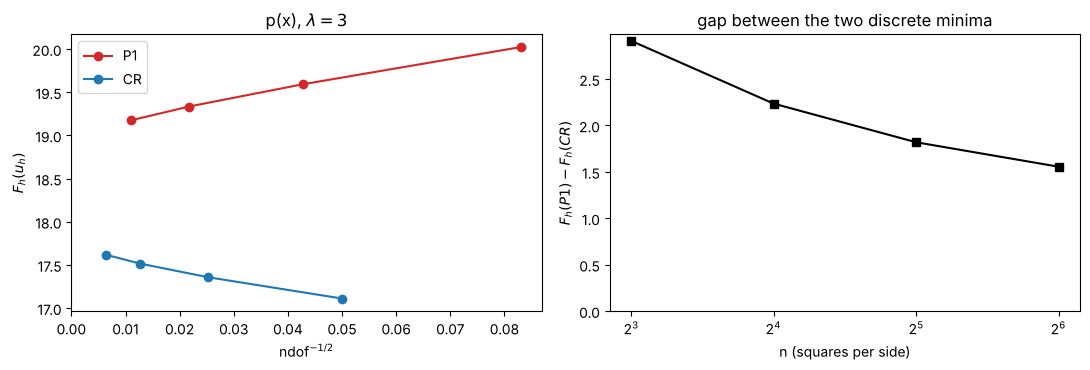

In [14]:
def plot_energies(rows, title):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    for s, c in (('P1', 'C3'), ('CR', 'C0')):
        R = [x for x in rows if x['scheme'] == s]
        h = np.array([1/np.sqrt(x['ndof']) for x in R]); E = np.array([x['energy'] for x in R])
        ax[0].plot(h, E, 'o-', c=c, label=s)
    ax[0].set_xlabel('ndof$^{-1/2}$'); ax[0].set_ylabel('$F_h(u_h)$'); ax[0].legend(); ax[0].set_title(title); ax[0].set_xlim(0)
    P = [x['energy'] for x in rows if x['scheme'] == 'P1']; Q = [x['energy'] for x in rows if x['scheme'] == 'CR']
    ns = [x['n'] for x in rows if x['scheme'] == 'P1']
    ax[1].plot(ns, np.array(P) - np.array(Q), 'ks-'); ax[1].set_xscale('log', base=2); ax[1].set_xlabel('n (squares per side)')
    ax[1].set_ylabel('$F_h(P1)-F_h(CR)$'); ax[1].set_title('gap between the two discrete minima'); ax[1].set_ylim(0)
    plt.tight_layout(); plt.show()
plot_energies(rows_px3, 'p(x), $\\lambda=3$')

The P1 energies decrease and the CR energies increase as $h\to0$, from opposite sides. The difference $F_h(\mathrm{P1})-F_h(\mathrm{CR})$ decreases only slowly (about 2.9, 2.2, 1.8, 1.6 on the four meshes), so these meshes cannot show whether it tends to a positive limit. The theory of the Lavrentiev gap predicts that it does: the P1 minima converge to $m_{\mathcal H}$ and the CR minima to $m_{\mathcal W}<m_{\mathcal H}$ (Carstensen–Ortner; Balci–Ortner–Storn). The convergence of each sequence is slow (Balci–Ortner–Storn report $\mathrm{ndof}^{-1/2}$ for the energies), so refining much further, or Richardson extrapolation in $\mathrm{ndof}^{-1/2}$, would be needed to see the limits.

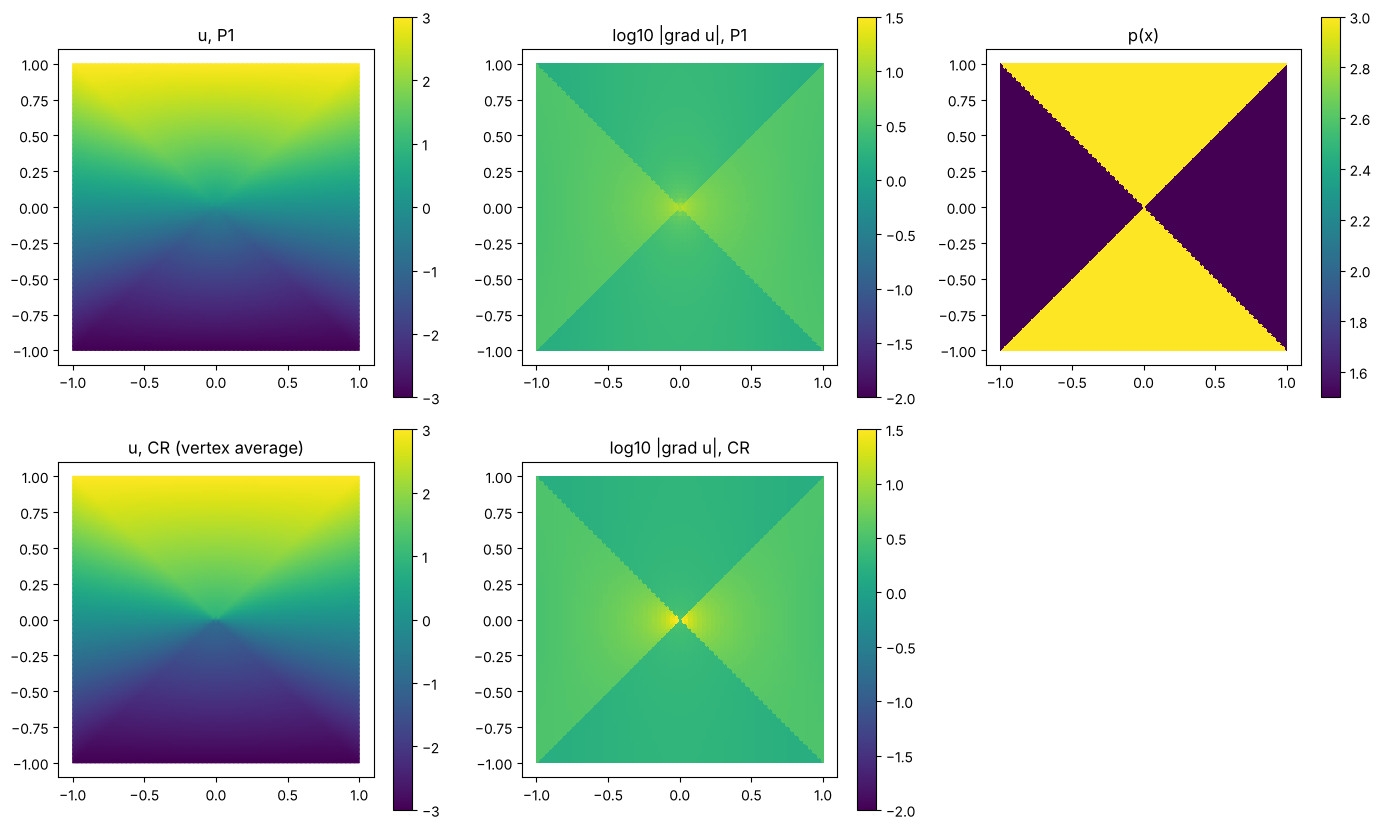

F_h: P1 = 19.174210316329273   CR = 17.618554920118008


In [15]:
# Solutions and gradient moduli on the finest mesh
mesh = crisscross_mesh(64); G = G_pxlap(); lam = 3.0
sP = GLaplaceSolver(mesh, G, 0.0, psi(lam), r=3.0); rP = sP.solve(tol=1e-8, stop='residual', max_iter=8000)
sC = GLaplaceCRSolver(mesh, G, 0.0, psi(lam), r=3.0); rC = sC.solve(tol=1e-8, stop='residual', max_iter=8000)
tri = mtri.Triangulation(mesh.vertices[:, 0], mesh.vertices[:, 1], mesh.triangles)
def gradmod(S, res): gx, gy = S.fem.gradient(res.u); return np.hypot(gx, gy)
fig, ax = plt.subplots(2, 3, figsize=(14, 8.4))
uP = rP.u; uC = sC.fem.nodal_average(rC.u)
for j, (u, nm) in enumerate(((uP, 'P1'), (uC, 'CR (vertex average)'))):
    c = ax[j, 0].tripcolor(tri, u, shading='gouraud'); plt.colorbar(c, ax=ax[j, 0]); ax[j, 0].set_title(f'u, {nm}')
for j, (S, res, nm) in enumerate(((sP, rP, 'P1'), (sC, rC, 'CR'))):
    g = gradmod(S, res)
    c = ax[j, 1].tripcolor(tri, facecolors=np.log10(g + 1e-12), vmin=-2, vmax=1.5); plt.colorbar(c, ax=ax[j, 1]); ax[j, 1].set_title(f'log10 |grad u|, {nm}')
c = ax[0, 2].tripcolor(tri, facecolors=p_zhikov()(sP.xb, sP.yb)); plt.colorbar(c, ax=ax[0, 2]); ax[0, 2].set_title('p(x)')
ax[1, 2].axis('off')
for a in ax.ravel(): a.set_aspect('equal')
plt.tight_layout(); plt.show()
print('F_h: P1 =', sP.energy(rP.u), '  CR =', sC.energy(rC.u))

## 4. Two-phase with discontinuous $a(x)$: $G=t^{3/2}/(3/2)+a(x)t^3/3$, $\lambda=1$ and $\lambda=3$

  lam=1 n=  8 P1 ndof=   145 it=   55 conv=True  F_h=3.181532 res=9.4e-09 (0.1s)


  lam=1 n=  8 CR ndof=   400 it=   87 conv=True  F_h=3.134213 res=8.8e-09 (0.2s)


  lam=1 n= 16 P1 ndof=   545 it=   65 conv=True  F_h=3.170657 res=8.7e-09 (0.2s)


  lam=1 n= 16 CR ndof=  1568 it=   96 conv=True  F_h=3.144343 res=9.6e-09 (0.2s)


  lam=1 n= 32 P1 ndof=  2113 it=   70 conv=True  F_h=3.165176 res=9.6e-09 (0.4s)


  lam=1 n= 32 CR ndof=  6208 it=  107 conv=True  F_h=3.149511 res=9.3e-09 (0.6s)


  lam=1 n= 64 P1 ndof=  8321 it=   74 conv=True  F_h=3.162311 res=1.0e-08 (1.4s)


  lam=1 n= 64 CR ndof= 24704 it=  119 conv=True  F_h=3.152242 res=9.5e-09 (2.7s)


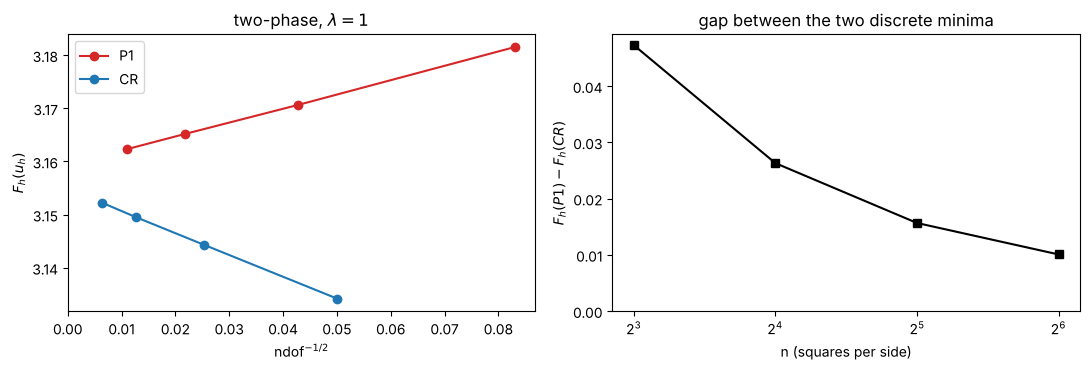

In [16]:
rows_tp1 = compare(G_twophase(), 1.0, ns=(8, 16, 32, 64), r=3.0, max_iter=8000)
plot_energies(rows_tp1, 'two-phase, $\\lambda=1$')

  lam=3 n=  8 P1 ndof=   145 it=   88 conv=True  F_h=24.722815 res=9.2e-09 (0.1s)


  lam=3 n=  8 CR ndof=   400 it=  151 conv=True  F_h=20.034090 res=9.4e-09 (0.3s)


  lam=3 n= 16 P1 ndof=   545 it=   90 conv=True  F_h=24.066925 res=1.0e-08 (0.2s)


  lam=3 n= 16 CR ndof=  1568 it=  181 conv=True  F_h=20.394791 res=9.8e-09 (0.5s)


  lam=3 n= 32 P1 ndof=  2113 it=  107 conv=True  F_h=23.671279 res=9.6e-09 (0.6s)


  lam=3 n= 32 CR ndof=  6208 it=  219 conv=True  F_h=20.626710 res=9.8e-09 (1.4s)


  lam=3 n= 64 P1 ndof=  8321 it=  119 conv=True  F_h=23.423860 res=9.8e-09 (2.7s)


  lam=3 n= 64 CR ndof= 24704 it=  267 conv=True  F_h=20.778355 res=9.8e-09 (6.0s)


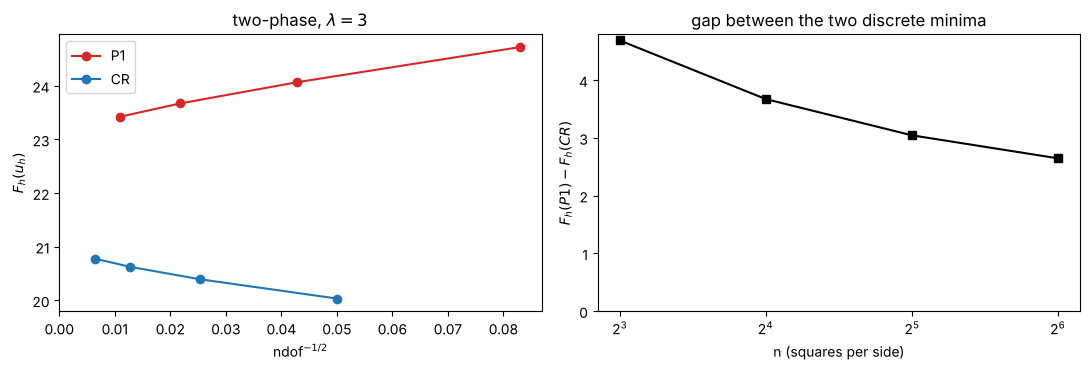

In [17]:
rows_tp3 = compare(G_twophase(), 3.0, ns=(8, 16, 32, 64), r=3.0, max_iter=8000)
plot_energies(rows_tp3, 'two-phase, $\\lambda=3$')

## 5. Dependence on the scaling $\lambda$ ($p(x)$ problem, $n=32$)
For small $\lambda$ the two schemes should agree (no gap); the difference should grow for large $\lambda$. This is **evidence at fixed $h$, not a proof**:
at a fixed mesh the two discrete minima always differ, so the statement concerns the limit $h\to0$ (compare the previous sections).

lambda=0.25: F_h(P1)=0.14443  F_h(CR)=0.14434  difference=0.00010  relative=6.61e-04


lambda=0.50: F_h(P1)=0.51390  F_h(CR)=0.51370  difference=0.00020  relative=3.94e-04


lambda=1.00: F_h(P1)=2.00000  F_h(CR)=2.00000  difference=-0.00000  relative=-1.11e-16


lambda=1.50: F_h(P1)=4.52781  F_h(CR)=4.51002  difference=0.01779  relative=3.94e-03


lambda=2.00: F_h(P1)=8.16899  F_h(CR)=7.99207  difference=0.17691  relative=2.21e-02


lambda=3.00: F_h(P1)=19.33503  F_h(CR)=17.51571  difference=1.81931  relative=1.04e-01


lambda=4.00: F_h(P1)=36.83111  F_h(CR)=29.95702  difference=6.87408  relative=2.29e-01


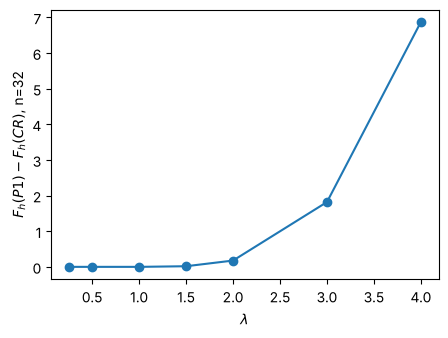

In [18]:
lams = [0.25, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0]
diff = []
for lam in lams:
    r = compare(G_pxlap(), lam, ns=(32,), r=max(1.0, lam), max_iter=10000, verbose=False)
    eP, eC = [x['energy'] for x in r]; diff.append(eP - eC)
    print(f'lambda={lam:4.2f}: F_h(P1)={eP:.5f}  F_h(CR)={eC:.5f}  difference={eP-eC:.5f}  relative={(eP-eC)/eC:.2e}')
plt.figure(figsize=(5, 3.5)); plt.plot(lams, diff, 'o-'); plt.xlabel('$\\lambda$'); plt.ylabel('$F_h(P1)-F_h(CR)$, n=32'); plt.show()

## 6. Remarks / caveats

* The comparison is about the **energies of the discrete minimisers**. Theorem C of the paper only gives convergence of the iteration at each fixed mesh; it says nothing about $h\to0$.
* That CR converges to the $\mathcal W$-minimiser is the theorem of Balci–Ortner–Storn (2022) under their assumptions (A) (growth conditions; $x_T$ chosen so that the integrand is evaluated at a point of $T$, with $p(x)$ constant on each triangle here because the mesh resolves the interface); for the *two-phase* problem with discontinuous $a$ and $e^t$-type integrands we have not checked that the assumptions hold.
* Observed convergence of $F_h$ is slow and the difference between the two schemes still decreases on the finest meshes: the limits of the two sequences cannot be read off from four meshes.
* For discontinuous Galerkin we know of no convergence theorem in the presence of a gap; CR is the method with theory.